In [29]:
import torch 
import torch.nn as nn

In [30]:
input =  torch.tensor([[0.7, 0.6]])

weights = torch.tensor([[0.9,0.4],
                        [-0.3,0.6],
                        [0.5,-0.5]])

biases = torch.tensor([0.2,-0.1,0.0])

# Linear Combinartion -> wX + b
raw_output = torch.matmul(input, weights.T ) + biases
raw_output

tensor([[1.0700, 0.0500, 0.0500]])

In [31]:
# Using in built functiion same ops as above

pytorch_layer = nn.Linear(in_features=2,out_features=3)

pytorch_layer.weight.data = weights
pytorch_layer.bias.data = biases

output = pytorch_layer(input)
output

tensor([[1.0700, 0.0500, 0.0500]], grad_fn=<AddmmBackward0>)

In [32]:
# Activation Function
z = output
# 1. sigmoid 
sigmoid_output = torch.sigmoid(output)

# 2. Tanh
tanh_output = torch.tanh(z)

# 3. Relu
relu_output = torch.relu(z)
  

In [33]:
print(sigmoid_output)
print(tanh_output)
print(relu_output)

tensor([[0.7446, 0.5125, 0.5125]], grad_fn=<SigmoidBackward0>)
tensor([[0.7895, 0.0500, 0.0500]], grad_fn=<TanhBackward0>)
tensor([[1.0700, 0.0500, 0.0500]], grad_fn=<ReluBackward0>)


In [34]:
# Custom Pytorch Neural Network Model 
# 2 inputs
# 16 Perceptron


class NNModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Layer 1 
        self.layer1 = nn.Linear(in_features=2,out_features=16)

        # Layer 2
        self.layer2 = nn.Linear(in_features=16,out_features=4)

        # Layer 3
        self.layer3 = nn.Linear(in_features=4,out_features=1)

        


    def forward(self, x):

        # step 1 : Linear Combination
        x = self.layer1(x)

        # Step 2 : Layer 1 Activation Function
        x = torch.relu(x)

        # Step 3 : Layer 2 Linear Combination
        x = self.layer2(x)

        # step 4 : Layer 2 Activation Function
        x = torch.relu(x)

        # Step 5 : Layer 3 Linear Comb
        x = self.layer3(x)

        # Step 6 : Layer 3 Activation Function
        x = torch.relu(x)



        return output



model = NNModel()

data = torch.randn(2,2)

predictions = model(data)


print(data)
print(predictions)


tensor([[ 0.4567, -1.2222],
        [-1.2357, -3.2577]])
tensor([[1.0700, 0.0500, 0.0500]], grad_fn=<AddmmBackward0>)


In [35]:
# Backward Propagation

import torch
import torch.nn as nn
import torch.optim as optim

# Input
X = torch.tensor([[0.0,0.0],
                  [0.0,1.0],
                  [1.0,0.0],
                  [1.0,1.0]])
# Actual Output
y_act = torch.tensor([[0.0],
                      [1.0],
                      [1.0],
                      [0.0]])

# Define the neural network
class NNModel(nn.Module):
    def __init__(self):
        super(NNModel,self).__init__()

        # Layer 1
        self.layer1 = nn.Linear(2,4)

        # Layer 2
        self.layer2 = nn.Linear(4,1)

    def forward(self,x):

        # step 1 : Linear Combination
        x = self.layer1(x)

        # step 2 : Layer 1 Activation Function
        x = torch.relu(x)

        # step 3 : Layer 2 Linear Combination
        x = self.layer2(x)

        # step 4 : Layer 2 Activation Function
        x = torch.sigmoid(x)

        return x


model = NNModel()

# Loss Function
# MSE is used for regression problems
# Classification problems -> Binary Cross Entropy Loss Function

criterion = nn.BCELoss()

optimizer = optim.SGD(model.parameters(), lr=0.1) # Stochastic Gradient Descent 

epochs = 7000

for epoch in range(epochs):

    predictions = model(X)

    loss = criterion(predictions, y_act)

    optimizer.zero_grad() # Gradients/Slope/Differentiation is being calcuated in every step # We need to reset the calculation for each new step

    loss.backward() # Calculate new gradients/slope

    optimizer.step() # Update the weights, take a step

    print(f'Epoch [{epoch + 1}/{epoch}], Loss: {loss.item():.4f}')

print(f'Loss: {loss.item():.4f}')

Epoch [1/0], Loss: 0.6912
Epoch [2/1], Loss: 0.6897
Epoch [3/2], Loss: 0.6882
Epoch [4/3], Loss: 0.6868
Epoch [5/4], Loss: 0.6855
Epoch [6/5], Loss: 0.6841
Epoch [7/6], Loss: 0.6828
Epoch [8/7], Loss: 0.6819
Epoch [9/8], Loss: 0.6807
Epoch [10/9], Loss: 0.6798
Epoch [11/10], Loss: 0.6787
Epoch [12/11], Loss: 0.6778
Epoch [13/12], Loss: 0.6768
Epoch [14/13], Loss: 0.6758
Epoch [15/14], Loss: 0.6750
Epoch [16/15], Loss: 0.6740
Epoch [17/16], Loss: 0.6733
Epoch [18/17], Loss: 0.6723
Epoch [19/18], Loss: 0.6715
Epoch [20/19], Loss: 0.6707
Epoch [21/20], Loss: 0.6697
Epoch [22/21], Loss: 0.6692
Epoch [23/22], Loss: 0.6682
Epoch [24/23], Loss: 0.6674
Epoch [25/24], Loss: 0.6668
Epoch [26/25], Loss: 0.6658
Epoch [27/26], Loss: 0.6652
Epoch [28/27], Loss: 0.6645
Epoch [29/28], Loss: 0.6636
Epoch [30/29], Loss: 0.6630
Epoch [31/30], Loss: 0.6622
Epoch [32/31], Loss: 0.6613
Epoch [33/32], Loss: 0.6608
Epoch [34/33], Loss: 0.6600
Epoch [35/34], Loss: 0.6591
Epoch [36/35], Loss: 0.6586
Epoch [37/3

In [59]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1000 Random coordinatea b/w -1 and 1
X = (torch.rand(1000, 2) * 2 ) - 1

# Label 1 if inside a radicious of 0.7, label 0 if outside

radicious_squared = 0.7 ** 2
y_act = (X[:,0]**2 + X[:,1]**2 < radicious_squared).float().view(-1,1)

print(X.shape)


torch.Size([1000, 2])


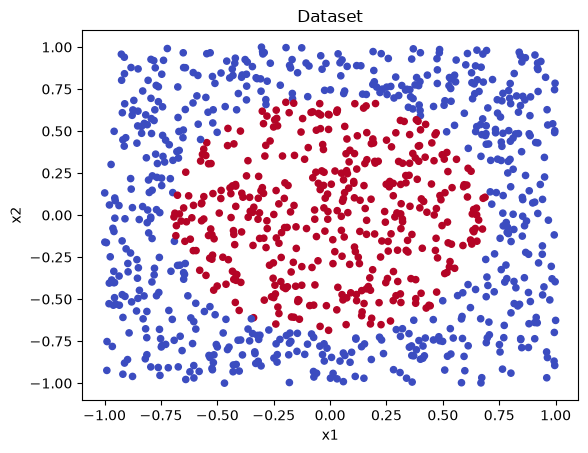

In [60]:
import matplotlib.pyplot as plt 
plt.scatter(X[:,0], X[:,1], c = y_act.squeeze(), cmap='coolwarm', s =20)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title('Dataset')
plt.show()

In [61]:
# Define the neural network
class NNModel(nn.Module):
    def __init__(self):
        super(NNModel,self).__init__()

        # Layer 1
        self.layer1 = nn.Linear(2,30)

        # Layer 2
        self.layer2 = nn.Linear(30, 1)

   


    def forward(self,x):

        # step 1 : Linear Combination
        x = self.layer1(x)

        # step 2 : Layer 1 Activation Function
        x = torch.relu(x)

        # step 3 : Layer 2 Linear Combination
        x = self.layer2(x)

        # step 4 : Layer 2 Activation Function
        x = torch.sigmoid(x)

        

        return x

In [ ]:
model = NNModel()

# Loss Function
# MSE is used for regression problems
# Classification problems -> Binary Cross Entropy Loss Function

criterion = nn.BCELoss()

optimizer = optim.SGD(model.parameters(), lr=0.1) # Stochastic Gradient Descent 

epochs = 10000

for epoch in range(epochs):

    predictions = model(X)

    loss = criterion(predictions, y_act)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()
    
    print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

RuntimeError: mat1 and mat2 shapes cannot be multiplied (10000x1 and 2x30)

In [ ]:
model.eval()

with torch.no_grad():
    probabilities = torch.sigmoid(model(X))
    predicted_labels = (probabilities >= 0.5).float()

    accuracy = (predicted_labels == y_act).float().mean()

    print(f"Training accuracy: {accuracy.item():.4%}")
    

Training accuracy: 37.6000%


In [41]:
for name, parameter in model.named_parameters():
    print(
        name,
        parameter.grad.norm().item()
        if parameter.grad is not None else None
    )

print(model)

layer1.weight 0.0032885607797652483
layer1.bias 0.001881877426058054
layer2.weight 0.0036022476851940155
layer2.bias 0.00028791208751499653
NNModel(
  (layer1): Linear(in_features=2, out_features=30, bias=True)
  (layer2): Linear(in_features=30, out_features=1, bias=True)
)


Overfitting in NN

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
import math

# Dataset
torch.manual_seed(42)

def generate_data(num_points):

    X = (torch.rand(num_points, 1) * 8) - 4

    noise = torch.rand(num_points, 1) * 0.3

    y = torch.sin(X) + noise
    return X, y

In [51]:
# Training set : Here I am deliberatrly trying to overfit for demonstration
X_train, y_train = generate_data(30000)

X_val, y_val = generate_data(10000)

class NNModel(nn.Module):
    def __init__(self):
        super(NNModel,self).__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128,128),
            nn.ReLU(),
            nn.Linear(128,1)
        )
        # weghts = 128 + 128 * 128 + 128, Biases = 128 + 128 + 1

    def forward(self, x):
        return self.net(x)


model = NNModel()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr= 0.01)

In [52]:
writer = SummaryWriter('runs//demo')


In [53]:
epochs = 800

for epoch in range(epochs):             

    #---------------Training Phase------------------------
    model.train()
    #Forward Pass
    train_preds = model(X_train)

    #Loss calculation
    train_loss = criterion(train_preds, y_train)

    # Backward pass
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    #------------Validation Phase------------------
    model.eval() # set to evaluation mode

    with torch.no_grad():
        val_preds = model(X_val)
        val_loss = criterion(val_preds,y_val)


    # -----------Logging to Graphs----------------
    # We Group them under the name 'Loss' so they appear on the same graph
    writer.add_scalars('Loss',{
        'Train': train_loss.item(),
        'Validation': val_loss.item()
    }, epoch)

writer.close()
print(f"Final Train Loss:{train_loss.item():.4f}")
print(f"Final validation  Loss:{val_loss.item():.4f}")

Final Train Loss:0.0076
Final validation  Loss:0.0076


In [54]:
!tensorboard --logdir=runs

TensorFlow installation not found - running with reduced feature set.

NOTE: Using experimental fast data loading logic. To disable, pass
    "--load_fast=false" and report issues on GitHub. More details:
    https://github.com/tensorflow/tensorboard/issues/4784

Serving TensorBoard on localhost; to expose to the network, use a proxy or pass --bind_all
TensorBoard 2.21.0 at http://localhost:6006/ (Press CTRL+C to quit)
^C


Early Stopping

In [11]:
import torch 
import numpy as np

class EarlyStopper:
    def __init__(self,patience=5,min_delta=0.001):

        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = np.inf
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):

        if val_loss < self.best_loss - self.min_delta:
            self.counter = 0
            self.best_loss = val_loss

        else:
            self.counter = self.counter + 1
            print(f'Early Stopping Counter : {self.counter} out of {self.patience}')

            if self.counter > self.patience:
                self.early_stop = True

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.tensorboard import SummaryWriter
import math

# Dataset
torch.manual_seed(42)

def generate_data(num_points):

    X = (torch.rand(num_points, 1) * 8) - 4

    noise = torch.rand(num_points, 1) * 0.3

    y = torch.sin(X) + noise
    return X, y

: 

In [13]:
# Training set : Here I am deliberatrly trying to overfit for demonstration
X_train, y_train = generate_data(3000)

X_val, y_val = generate_data(1000)

class NNModel(nn.Module):
    def __init__(self):
        super(NNModel,self).__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128,128),
            nn.ReLU(),
            nn.Linear(128,1)
        )
        # weghts = 128 + 128 * 128 + 128, Biases = 128 + 128 + 1

    def forward(self, x):
        return self.net(x)


model = NNModel()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr= 0.01)

In [14]:
writer = SummaryWriter('runs//demo')


In [ ]:
early_stopper = EarlyStopper()
epochs = 2000

for epoch in range(epochs):             

    #---------------Training Phase------------------------
    model.train()
    #Forward Pass
    train_preds = model(X_train)

    #Loss calculation
    train_loss = criterion(model(X_train), y_train)

    # Backward pass
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    #------------Validation Phase------------------
    model.eval() # set to evaluation mode

    with torch.no_grad():
        val_loss = criterion(model(X_val), y_val)
    print(f'Train Loss: {train_loss}')
    print(f'Validation Loss: {val_loss}')
        # Checking for early stopping
    early_stopper(val_loss.item(), model)

    if early_stopper.early_stop == True:
        print(f"Early stopping triggered at epoch {epoch}. Halting training.")
        break


    

: 

In [16]:
!tensorboard --logdir=runs

TensorFlow installation not found - running with reduced feature set.

NOTE: Using experimental fast data loading logic. To disable, pass
    "--load_fast=false" and report issues on GitHub. More details:
    https://github.com/tensorflow/tensorboard/issues/4784

Serving TensorBoard on localhost; to expose to the network, use a proxy or pass --bind_all
TensorBoard 2.21.0 at http://localhost:6006/ (Press CTRL+C to quit)
^C


Multi class Classification

----Sample Training Image-----


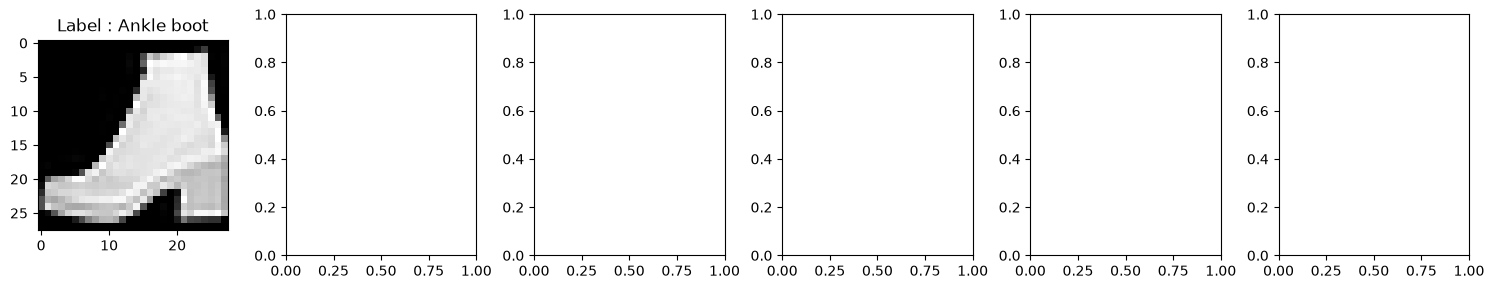

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [38]:
import torch
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt


transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

classes = train_data.classes

def show_images(images, labels, preds= None):

    fig, axes = plt.subplots(1, 6, figsize=(15,3))
    for i, ax in enumerate(axes):
        ax.imshow(images[i].squeeze(), cmap="gray")

        true_label = classes[labels[i]]
        if preds is not None:
            pred_label = classes[preds[i].item()]
            color = "green" if preds[i] == labels[i] else "red"
            ax.set_title(f"True: {true_label}\nPred: {pred_label}", color= color, fontweight='bold')

        else:
            ax.set_title(f"Label: {true_label}")

        ax.set_title(f"Label : {true_label}")


        plt.tight_layout()
        plt.show()

print("----Sample Training Image-----")
sample_imgs, sample_1bls = next(iter(train_loader))
show_images(sample_imgs, sample_1bls)


---- Sample Training Images ----


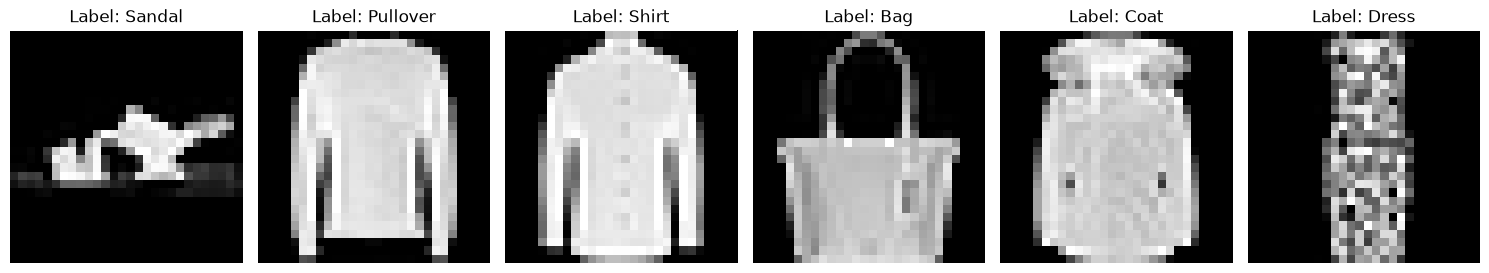

In [44]:
def show_images(images, labels, preds=None):

    fig, axes = plt.subplots(1, 6, figsize=(15, 3))

    for i in range(6):
        ax = axes[i]

        ax.imshow(images[i].squeeze(), cmap="gray")

        true_label = classes[labels[i].item()]

        if preds is not None:
            pred_label = classes[preds[i].item()]
            color = "green" if preds[i] == labels[i] else "red"

            ax.set_title(
                f"True: {true_label}\nPred: {pred_label}",
                color=color,
                fontweight="bold"
            )
        else:
            ax.set_title(f"Label: {true_label}")

        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("---- Sample Training Images ----")

sample_imgs, sample_lbls = next(iter(train_loader))

show_images(sample_imgs, sample_lbls)


In [50]:
model = nn.Sequential(
    nn.Flatten(), # Convert 2d data to 1d data to feed into NN
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
    # No need to write Softmax Func explicitly, CrossEntropyLoss() handles it automatically
)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct= 0
    total_samples = 0

    for images,labels in train_loader:
        # Forward pass
        predictions = model(images)
        loss = criterion(predictions, labels)

        # Baxkward pass & Optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Trach Matrics
        total_loss += loss.item()

        # calculate accuracy for this batch
        predicted_classes = predictions.argmax(dim=1)
        correct += (predicted_classes == labels).sum().item()
        total_samples += labels.size(0)

    avg_loss = total_loss / len(train_loader)
    accuracy = (correct / total_samples) * 100
    print(f"Epoch [{epoch + 1}/{epochs}] | Loss : {avg_loss:.4f} | Training Accuracy : {accuracy:.2f}%")



Epoch [1/5] | Loss : 0.5473 | Training Accuracy : 80.39%
Epoch [2/5] | Loss : 0.3940 | Training Accuracy : 85.66%
Epoch [3/5] | Loss : 0.3562 | Training Accuracy : 86.76%
Epoch [4/5] | Loss : 0.3347 | Training Accuracy : 87.62%
Epoch [5/5] | Loss : 0.3204 | Training Accuracy : 88.07%



 --- test set prediciotions----


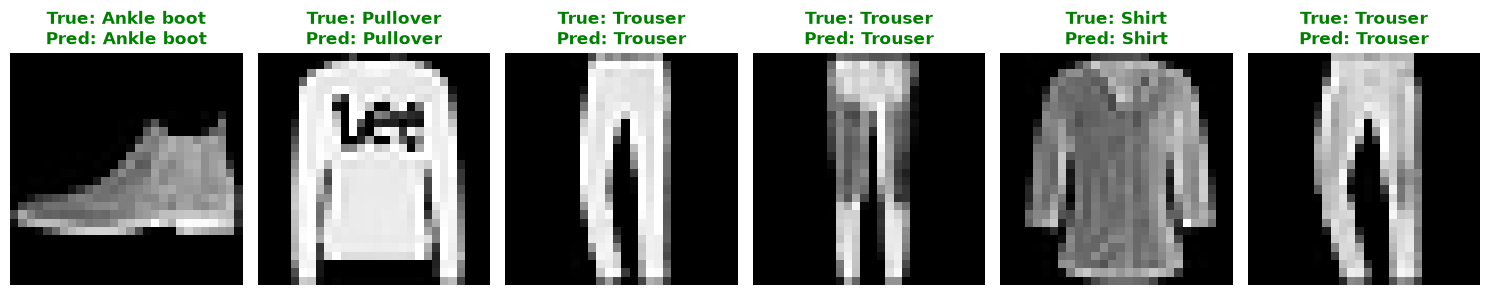

In [52]:
print("\n --- test set prediciotions----")
model.eval()

test_imgs, test_lbls = next(iter(test_loader))

with torch.no_grad():
    raw_outputs = model(test_imgs)

    test_preds = raw_outputs.argmax(dim=1)

show_images(test_imgs, test_lbls, test_preds)

Racing optimizers... This may take a few seconds.


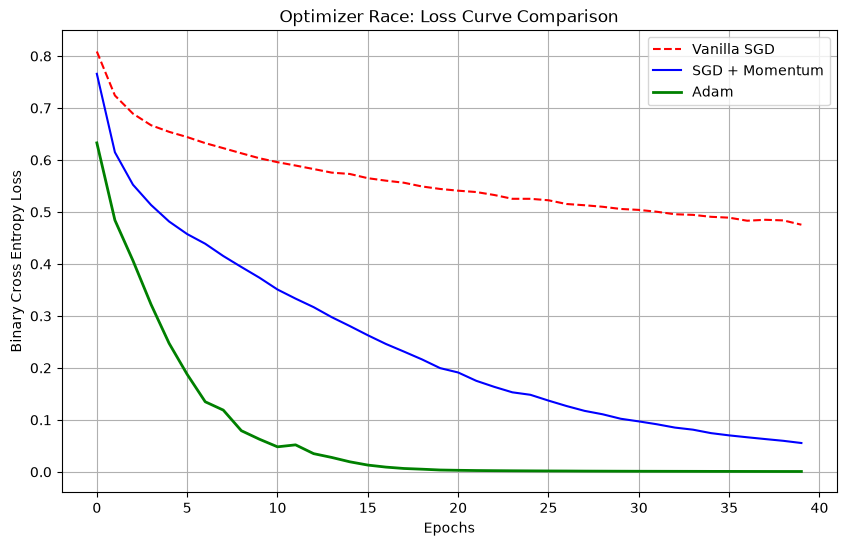

In [53]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

# ==========================================
# 1. ABSTRACTION: Dataset & Mini-Batches
# ==========================================
# Create a synthetic non-linear dataset (1000 points)
torch.manual_seed(42)
X = torch.randn(1000, 20)
# A complex target function to force the network to work hard
y = (X[:, 0] * X[:, 1] + torch.sin(X[:, 2]) > 0).float().view(-1, 1)

dataset = TensorDataset(X, y)

# The Goldilocks Zone: Mini-Batch of 64
# Setting batch_size=64 is what makes this "Mini-Batch Gradient Descent"
loader = DataLoader(dataset, batch_size=64, shuffle=True)

# ==========================================
# 2. THE MODEL FACTORY
# ==========================================
def create_model():
    """Creates a fresh, un-trained model with He Initialization."""
    model = nn.Sequential(
        nn.Linear(20, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1),
        nn.Sigmoid()
    )

    # Apply He Initialization explicitly (PyTorch often does a variant by default)
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
            nn.init.zeros_(layer.bias)

    return model

# ==========================================
# 3. THE OPTIMIZER RACE
# ==========================================
def train_model(optimizer_name):
    model = create_model()
    criterion = nn.BCELoss()

    # Configure the specific optimizer
    if optimizer_name == "SGD":
        optimizer = optim.SGD(model.parameters(), lr=0.01)
    elif optimizer_name == "Momentum":
        optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    elif optimizer_name == "Adam":
        optimizer = optim.Adam(model.parameters(), lr=0.01)

    epochs = 40
    loss_history = []

    for epoch in range(epochs):
        epoch_loss = 0
        # Mini-Batch processing
        for batch_X, batch_y in loader:
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        # Record the average loss for this epoch
        loss_history.append(epoch_loss / len(loader))

    return loss_history

print("Racing optimizers... This may take a few seconds.")
history_sgd = train_model("SGD")
history_momentum = train_model("Momentum")
history_adam = train_model("Adam")

# ==========================================
# 4. VISUALIZING THE RACE
# ==========================================
plt.figure(figsize=(10, 6))
plt.plot(history_sgd, label='Vanilla SGD', color='red', linestyle='--')
plt.plot(history_momentum, label='SGD + Momentum', color='blue')
plt.plot(history_adam, label='Adam', color='green', linewidth=2)

plt.title("Optimizer Race: Loss Curve Comparison")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()